# 01 · EDA — Flight Price (Regression)
Explore the data to guide preprocessing and model choice. Figures are saved to `results/regression/figures/`.

## Setup
Make `src/` importable and load the shared config (seed, paths).

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

# Make `src` importable: repo root locally, or an uploaded Kaggle dataset containing src/
for p in [Path.cwd(), *Path.cwd().parents, *(f.parent.parent for f in Path("/kaggle/input").glob("**/src/config.py"))]:
    if (p / "src" / "config.py").exists():
        sys.path.insert(0, str(p.resolve()))
        break

from src import config

Load the data.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

TASK = "regression"
FIG_DIR = config.results_dir(TASK) / "figures"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)

def save(name):
    """Save the current figure for the report, then show it."""
    plt.savefig(FIG_DIR / f"eda_{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

train, test, sample_sub = config.load(TASK)
TARGET = config.TARGETS[TASK]

# Fixed category orders so every plot reads the same way
STOPS = ["zero", "one", "two_or_more"]
SLOTS = ["Early_Morning", "Morning", "Afternoon", "Evening", "Night", "Late_Night"]
CLASSES = ["Economy", "Business"]

print("train", train.shape, "| test", test.shape, "| sample_submission", sample_sub.shape)
train.head()

train (15589, 12) | test (3898, 11) | sample_submission (3898, 2)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,1,Wayfarer Aviation,IX 1070,Metropolis,Evening,zero,Night,Springfield,Economy,NaN,18,8909
1,2,Oceanic Airlines,6E 285,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,5115
2,3,Wayfarer Aviation,AI 2641,Night City,Evening,zero,Night,Springfield,Business,2.08,13,35247
3,4,Oceanic Airlines,6E 6704,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6457
4,5,Oceanic Airlines,6E 234,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6842


Column types and missing values.

In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                15589 non-null  int64  
 1   airline           12500 non-null  object 
 2   flight            15589 non-null  object 
 3   source_city       15589 non-null  object 
 4   departure_time    15589 non-null  object 
 5   stops             15589 non-null  object 
 6   arrival_time      15589 non-null  object 
 7   destination_city  15589 non-null  object 
 8   flight_class      15589 non-null  object 
 9   duration          12494 non-null  float64
 10  days_left         15589 non-null  int64  
 11  price             15589 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 1.4+ MB


## Target distribution

count     15589.0
mean      29817.0
std       39128.0
min        3801.0
25%        7210.0
50%       10183.0
75%       35968.0
max      323177.0

skewness raw: 2.70 | skewness log: 0.71


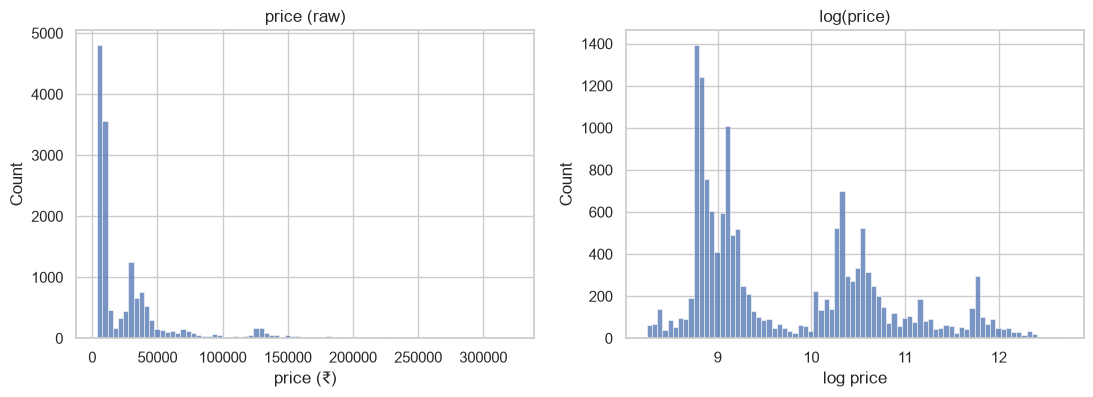

In [4]:
print(train[TARGET].describe().round(0).to_string())
print(f"\nskewness raw: {train[TARGET].skew():.2f} | skewness log: {np.log(train[TARGET]).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train[TARGET], bins=80, ax=axes[0])
axes[0].set(title="price (raw)", xlabel="price (₹)")
sns.histplot(np.log(train[TARGET]), bins=80, ax=axes[1])
axes[1].set(title="log(price)", xlabel="log price")
save("2_1_target")

- Price is right-skewed (median ₹10,183, mean ₹29,817); log(price) has two humps.

## Cabin class

               count     mean      std      min      25%      50%      75%       max
flight_class                                                                        
Business      6380.0  60127.0  46415.0  15544.0  30767.0  38546.0  70441.0  323177.0
Economy       9209.0   8818.0   4670.0   3801.0   6740.0   7587.0   9340.0   74691.0


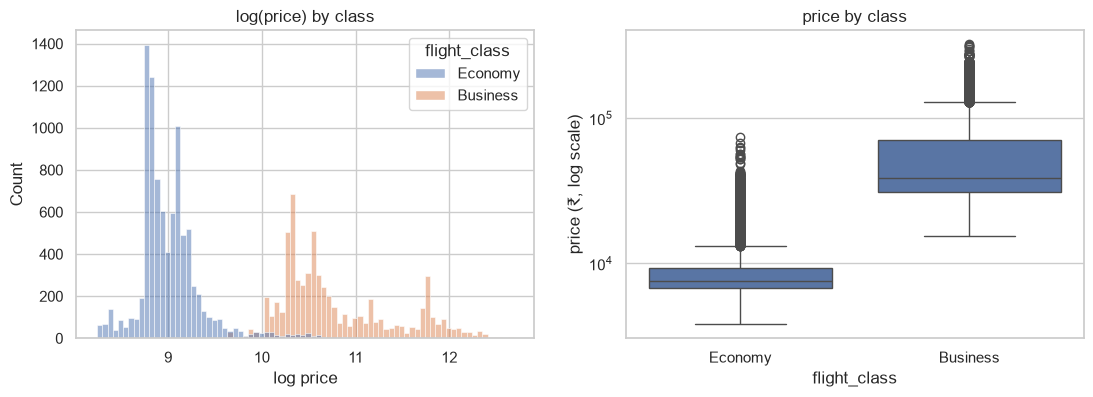


median Business / median Economy = 5.1x


In [5]:
print(train.groupby("flight_class")[TARGET].describe().round(0).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=train, x=np.log(train[TARGET]), hue="flight_class", hue_order=CLASSES, bins=80, ax=axes[0])
axes[0].set(title="log(price) by class", xlabel="log price")
sns.boxplot(data=train, x="flight_class", y=TARGET, order=CLASSES, ax=axes[1])
axes[1].set(title="price by class", yscale="log", ylabel="price (₹, log scale)")
save("2_2_class")

ratio = train.groupby("flight_class")[TARGET].median()
print(f"\nmedian Business / median Economy = {ratio['Business'] / ratio['Economy']:.1f}x")

- Business median is 5.1× Economy; the two classes barely overlap.

## Airline
Rows, Business share and median price per airline.

In [6]:
air = (train.groupby("airline")
          .agg(n=(TARGET, "size"),
               business_share=("flight_class", lambda s: (s == "Business").mean()),
               median_price=(TARGET, "median"))
          .sort_values("n", ascending=False))
air["business_share"] = air["business_share"].round(2)
air

,n,business_share,median_price
airline,,,
Wayfarer Aviation,5200,0.48,14200.5
Oceanic Airlines,5112,0.26,8759.0
Sandpiper Air,697,0.03,7851.0
Stark Aviation,336,0.91,130960.0
Ajira Airways,330,0.84,71716.0
Nakatomi Airlines,319,0.88,133515.0
Wayne Enterprises Air,180,0.93,101561.5
Vandelay Aviation,115,0.00,7719.0
Virtucon,85,0.99,133809.0


Price by airline within each class (airlines with ≥ 50 rows).

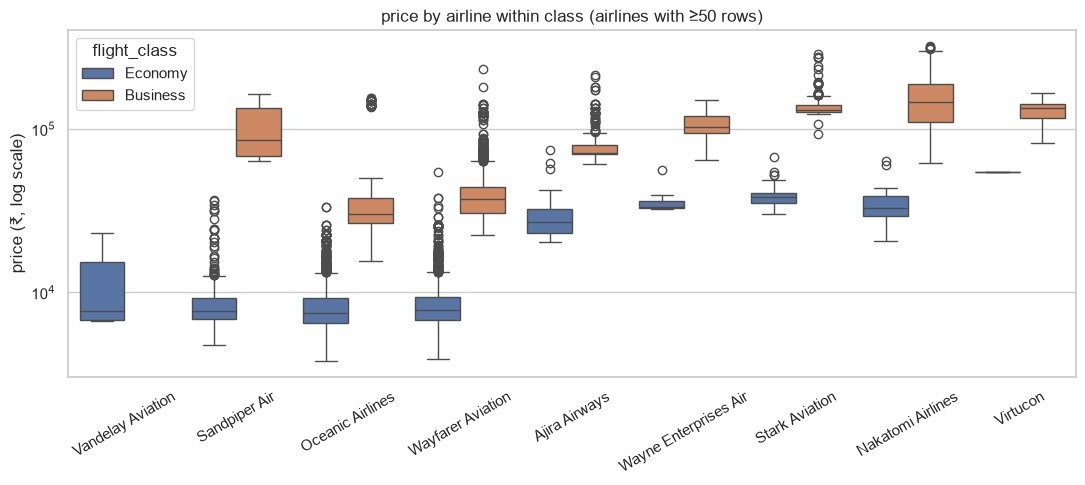

In [7]:
top = air.index[air["n"] >= 50]
sub = train[train["airline"].isin(top)]
order = sub.groupby("airline")[TARGET].median().sort_values().index

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.boxplot(data=sub, x="airline", y=TARGET, hue="flight_class", hue_order=CLASSES, order=order, ax=ax)
ax.set(yscale="log", ylabel="price (₹, log scale)", xlabel="", title="price by airline within class (airlines with ≥50 rows)")
ax.tick_params(axis="x", rotation=30)
save("2_3_airline")

Share of log-price variance explained by one feature (R² of group means).

In [8]:
# How much of the spread in log(price) does a single grouping explain? (R² of predicting each row by its group mean)
def r2_by_group(df, col):
    y = np.log(df[TARGET])
    return 1 - ((y - y.groupby(df[col]).transform("mean")) ** 2).sum() / ((y - y.mean()) ** 2).sum()

print(f"all rows   | flight_class alone: R² = {r2_by_group(train, 'flight_class'):.2f}")
known = train.dropna(subset=["airline"])
for cls in CLASSES:
    print(f"{cls:10s} | airline alone:      R² = {r2_by_group(known[known.flight_class == cls], 'airline'):.2f}")

# Economy tickets above ₹20k: which airlines sell them?
eco = train[train["flight_class"] == "Economy"]
print("\nshare of Economy tickets > ₹20k, by airline:")
print(eco.groupby("airline")[TARGET].apply(lambda s: (s > 20_000).mean()).round(2).sort_values().to_string())

all rows   | flight_class alone: R² = 0.78
Economy    | airline alone:      R² = 0.32
Business   | airline alone:      R² = 0.76

share of Economy tickets > ₹20k, by airline:
airline
Massive Dynamic          0.00
Hooli Airways            0.00
Oceanic Airlines         0.01
Wayfarer Aviation        0.01
Sandpiper Air            0.02
Vandelay Aviation        0.08
Ajira Airways            1.00
Black Mesa Air           1.00
Omni Consumer Flights    1.00
Nakatomi Airlines        1.00
Stark Aviation           1.00
Virtucon                 1.00
Wayne Enterprises Air    1.00


- Class alone explains R² 0.78; within Business, airline alone explains 0.76.
- Premium airlines sell Economy above ₹20k, so features act differently per class.

## Stops and duration

flight_class  Business  Economy
stops                          
zero              2821     8144
one               3495     1063
two_or_more         64        2

flight_class  Economy  Business
stops                          
zero           7555.0   33712.0
one            7697.0   61789.0
two_or_more   37996.0  125611.0


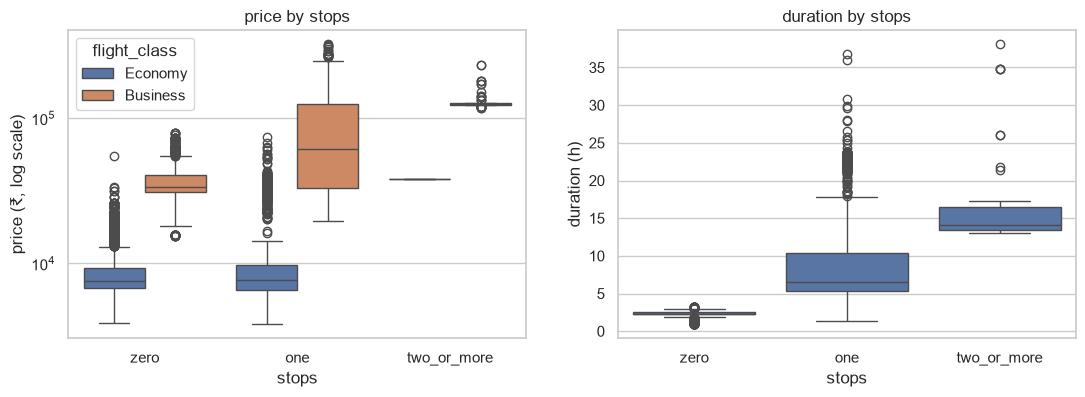

In [9]:
print(pd.crosstab(train["stops"], train["flight_class"]).reindex(STOPS).to_string())
print()
print(train.pivot_table(index="stops", columns="flight_class", values=TARGET, aggfunc="median")
      .reindex(STOPS)[CLASSES].round(0).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=train, x="stops", y=TARGET, hue="flight_class", order=STOPS, hue_order=CLASSES, ax=axes[0])
axes[0].set(yscale="log", ylabel="price (₹, log scale)", title="price by stops")
sns.boxplot(data=train, x="stops", y="duration", order=STOPS, ax=axes[1])
axes[1].set(title="duration by stops", ylabel="duration (h)")
save("2_4a_stops")

Price vs duration per class.

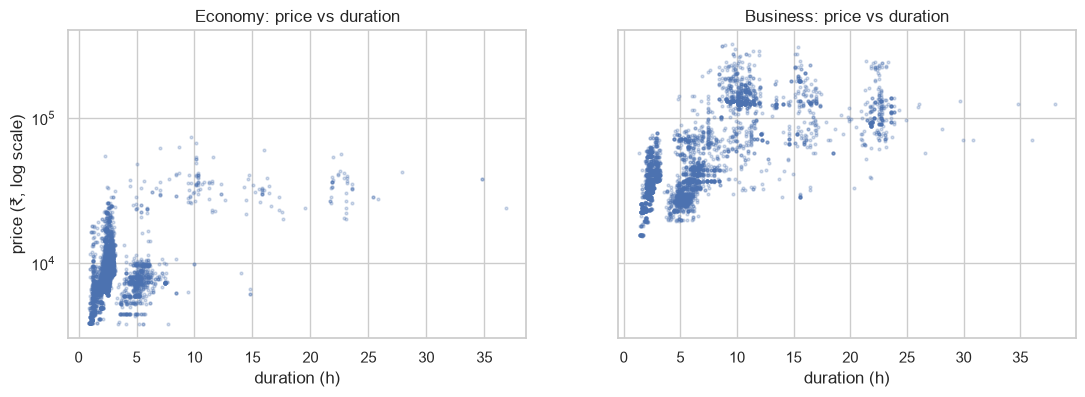

Economy   Spearman(duration, price) = 0.44
Business  Spearman(duration, price) = 0.68


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, cls in zip(axes, CLASSES):
    d = train[train["flight_class"] == cls]
    ax.scatter(d["duration"], d[TARGET], s=4, alpha=0.25)
    ax.set(title=f"{cls}: price vs duration", xlabel="duration (h)", yscale="log")
axes[0].set_ylabel("price (₹, log scale)")
save("2_4b_duration")

for cls in CLASSES:
    d = train[train["flight_class"] == cls].dropna(subset=["duration"])
    print(f"{cls:9s} Spearman(duration, price) = {d['duration'].corr(d[TARGET], method='spearman'):.2f}")

- Price rises with stops; stops and duration overlap.

## Days left before departure

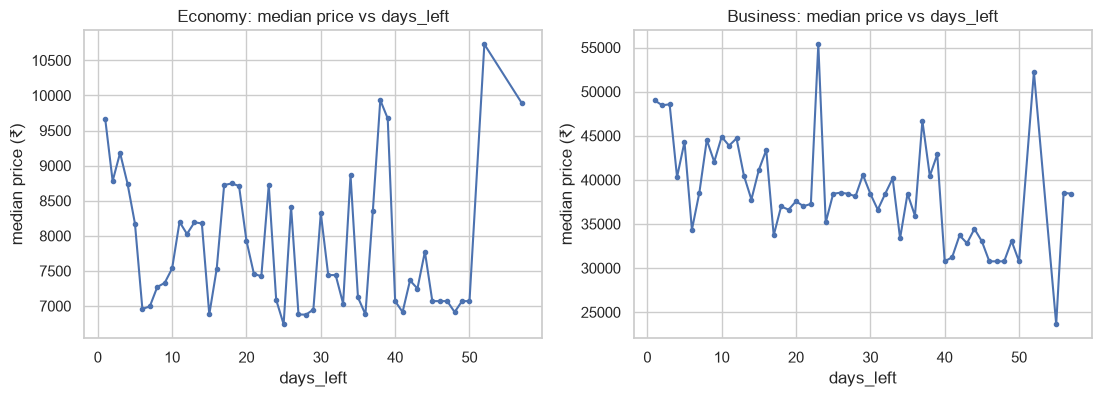

rows per days_left value: median 327 | min 15 at day 55
days_left values absent from train: [51, 53, 54]
tail (days > 49): {50: 124, 52: 107, 55: 15, 56: 26, 57: 97}
Economy   median price  days_left<=3:     9099 | 4-15:     7530 | >15:     7453
Business  median price  days_left<=3:    48562 | 4-15:    41506 | >15:    37771


In [11]:
dl = train.groupby(["flight_class", "days_left"])[TARGET].median().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, cls in zip(axes, CLASSES):
    d = dl[dl["flight_class"] == cls]
    ax.plot(d["days_left"], d[TARGET], marker="o", ms=3)
    ax.set(title=f"{cls}: median price vs days_left", xlabel="days_left", ylabel="median price (₹)")
save("2_5_days_left")

counts = train["days_left"].value_counts().sort_index()
print("rows per days_left value: median", int(counts.median()), "| min", counts.min(), "at day", counts.idxmin())
print("days_left values absent from train:", sorted(set(range(1, 58)) - set(counts.index)))
print("tail (days > 49):", counts[counts.index > 49].to_dict())

for cls in CLASSES:
    d = train[train["flight_class"] == cls]
    print(f"{cls:9s} median price  days_left<=3: {d.loc[d.days_left <= 3, TARGET].median():>8.0f}"
          f" | 4-15: {d.loc[d.days_left.between(4, 15), TARGET].median():>8.0f}"
          f" | >15: {d.loc[d.days_left > 15, TARGET].median():>8.0f}")

- Only the last ~4 days before departure show a clear price rise.

## Time slots and routes

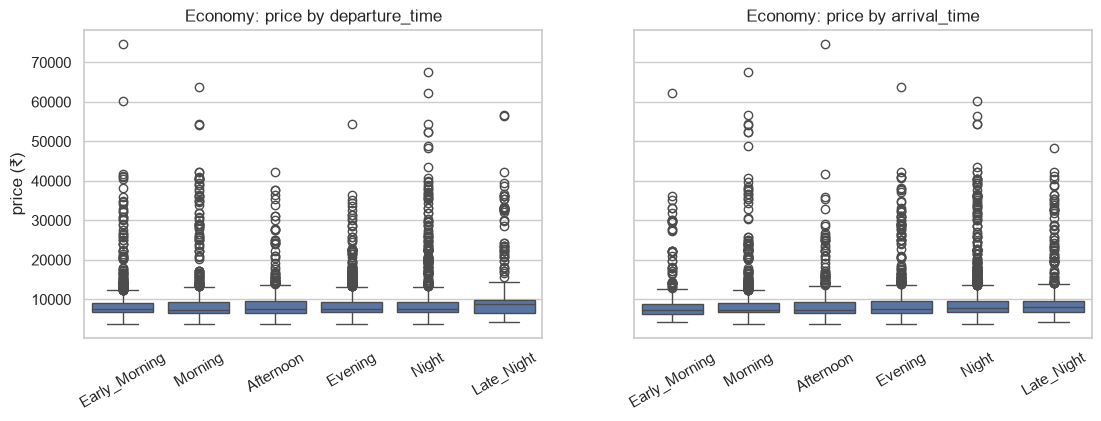

In [12]:
eco = train[train["flight_class"] == "Economy"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, col in zip(axes, ["departure_time", "arrival_time"]):
    sns.boxplot(data=eco, x=col, y=TARGET, order=SLOTS, ax=ax)
    ax.set(title=f"Economy: price by {col}", xlabel="", ylabel="price (₹)")
    ax.tick_params(axis="x", rotation=30)
save("2_6a_time_slots")

Economy median price per route.

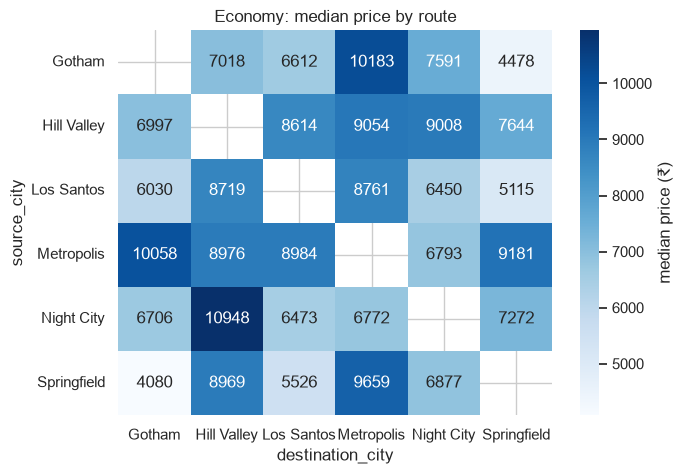

same source & destination rows: 0


In [13]:
eco_route = eco.pivot_table(index="source_city", columns="destination_city", values=TARGET, aggfunc="median")

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(eco_route, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar_kws={"label": "median price (₹)"})
ax.set(title="Economy: median price by route")
save("2_6b_routes")

print("same source & destination rows:", (train.source_city == train.destination_city).sum())

- Time slots barely matter; routes matter moderately.

## Missing values

In [14]:
miss = pd.DataFrame({"train_missing": train.isna().sum(), "test_missing": test.isna().sum()})
miss["train_%"] = (100 * miss["train_missing"] / len(train)).round(1)
miss = miss[(miss["train_missing"] > 0) | (miss["test_missing"] > 0)]
print(miss.to_string())

both = (train["airline"].isna() & train["duration"].isna()).sum()
print(f"\nrows missing both airline and duration: {both} "
      f"(≈{train['airline'].isna().mean() * train['duration'].isna().mean() * len(train):.0f} expected if independent)")

# Is missingness related to price? (If not, dropping/filling is less risky.)
for col in ["airline", "duration"]:
    m = train[col].isna()
    print(f"median price | {col} missing: {train.loc[m, TARGET].median():.0f} vs present: {train.loc[~m, TARGET].median():.0f}")

          train_missing  test_missing  train_%
airline            3089         799.0     19.8
duration           3095         776.0     19.9

rows missing both airline and duration: 602 (≈613 expected if independent)
median price | airline missing: 10213 vs present: 10183
median price | duration missing: 10269 vs present: 10183


- `airline` and `duration` are ~20% missing, independent of each other and of price.

Can `airline` be recovered from the flight-code prefix?

In [15]:
full = pd.concat([train.drop(columns=TARGET), test], ignore_index=True)
full["prefix"] = full["flight"].str.split().str[0]

per_prefix = full.dropna(subset=["airline"]).groupby("prefix")["airline"].nunique()
print("prefixes:", full["prefix"].nunique(), "| prefixes mapping to >1 airline:", (per_prefix > 1).sum())

per_airline = full.dropna(subset=["airline"]).groupby("airline")["prefix"].unique()
print(per_airline[per_airline.str.len() > 1].to_string())  # airlines that use more than one prefix

recoverable = full.loc[full["airline"].isna(), "prefix"].isin(per_prefix.index)
print(f"missing airline rows recoverable via prefix: {recoverable.sum()} / {len(recoverable)}")

prefixes: 20 | prefixes mapping to >1 airline: 0
airline
Wayfarer Aviation    [IX, AI]
missing airline rows recoverable via prefix: 3888 / 3888


- Every prefix maps to exactly one airline, so all missing airlines can be filled.

Can `duration` be recovered from the same flight, route and stops?

In [16]:
key = ["flight", "source_city", "destination_city", "stops"]
known = full.dropna(subset=["duration"])
spread = known.groupby(key)["duration"].agg(["size", "std"]).query("size > 1")
print(f"groups with ≥2 known durations: {len(spread)} | share with std == 0: {(spread['std'] == 0).mean():.1%}"
      f" | median std: {spread['std'].median():.2f} h")

has_group = full.loc[full["duration"].isna()].merge(
    known[key].drop_duplicates(), on=key, how="left", indicator=True)["_merge"].eq("both")
print(f"missing duration rows with a known same-group value: {has_group.sum()} / {len(has_group)}")

groups with ≥2 known durations: 1386 | share with std == 0: 76.1% | median std: 0.00 h
missing duration rows with a known same-group value: 3784 / 3871


- ~98% of missing durations have a known value in the same group.

## Duplicate rows

In [17]:
feats = [c for c in train.columns if c not in ("id", TARGET)]
dup_mask = train.duplicated(feats, keep=False)
g = train[dup_mask].groupby(feats, dropna=False)[TARGET]
spread = (g.max() - g.min())
print(f"rows sharing identical features with another row: {dup_mask.sum()} in {g.ngroups} groups")
print(f"groups whose prices differ: {(spread > 0).sum()} | median price gap within a group: {spread.median():.0f}")
exact = train.duplicated(feats + [TARGET], keep="first")
print(f"exact copies (features AND price identical, counting only the 2nd+ copy): {exact.sum()}"
      f" | spread over ids {train.loc[exact, 'id'].min()}–{train.loc[exact, 'id'].max()}")
print(f"ids: train {train.id.min()}–{train.id.max()}, test {test.id.min()}–{test.id.max()}"
      f" | sample_submission ids match test order: {(sample_sub.id.values == test.id.values).all()}")

rows sharing identical features with another row: 624 in 310 groups
groups whose prices differ: 35 | median price gap within a group: 0
exact copies (features AND price identical, counting only the 2nd+ copy): 279 | spread over ids 271–15585
ids: train 1–15589, test 1–3898 | sample_submission ids match test order: True


- Exact duplicate rows exist; they are dropped before CV.

## Train vs test

          column  max_share_diff_pct  test_values_unseen_in_train
         airline                1.70                            1
     source_city                1.13                            0
destination_city                0.63                            0
  departure_time                1.00                            0
    arrival_time                2.12                            0
           stops                0.42                            0
    flight_class                0.88                            0
duration  train mean 4.30 / test mean 4.25
days_left train mean 22.46 / test mean 22.21
airline names in test but not train: ['Tyrell Aeronautics'] | rows: 1 | their flight prefixes: ['BG']

test rows with a flight code never seen in train: 35 (0.9%)


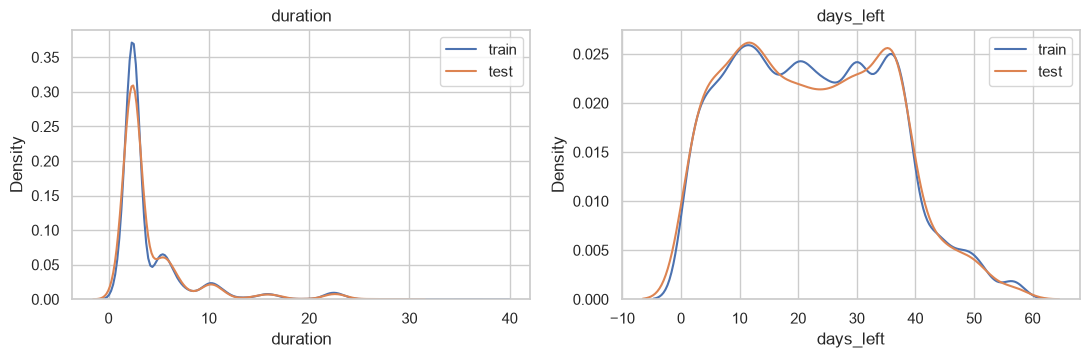

In [18]:
cats = ["airline", "source_city", "destination_city", "departure_time", "arrival_time", "stops", "flight_class"]
rows = []
for c in cats:
    p_tr = train[c].value_counts(normalize=True)
    p_te = test[c].value_counts(normalize=True)
    rows.append({"column": c, "max_share_diff_pct": round(100 * p_tr.subtract(p_te, fill_value=0).abs().max(), 2),
                 "test_values_unseen_in_train": len(set(test[c].dropna()) - set(train[c].dropna()))})
print(pd.DataFrame(rows).to_string(index=False))

for c in ["duration", "days_left"]:
    print(f"{c:9s} train mean {train[c].mean():.2f} / test mean {test[c].mean():.2f}")

new_air = sorted(set(test["airline"].dropna()) - set(train["airline"].dropna()))
print("airline names in test but not train:", new_air, "| rows:", test["airline"].isin(new_air).sum(),
      "| their flight prefixes:", test.loc[test["airline"].isin(new_air), "flight"].str.split().str[0].unique().tolist())
unseen = ~test["flight"].isin(train["flight"])
print(f"\ntest rows with a flight code never seen in train: {unseen.sum()} ({unseen.mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, c in zip(axes, ["duration", "days_left"]):
    sns.kdeplot(train[c], label="train", ax=ax); sns.kdeplot(test[c], label="test", ax=ax)
    ax.set(title=c); ax.legend()
save("2_8_train_vs_test")

- Test matches train closely; a few test flight codes are unseen, so encoders ignore unknown categories.

## Summary
| Finding | Decision |
|---|---|
| Class is the main factor, airline acts differently per class | class interactions for linear models |
| `airline` recoverable from flight code | exact fill before CV |
| `duration` recoverable from same flight group | group-median fill inside CV |
| Duplicate rows | drop before CV |
| `days_left`, time slots weak | no special features |